# Results and Discussion Pipeline
**Explicit and Implicit Navigation Guidance Effects on Player Wayfinding in Third-Person Open-World Games**
Narvasa, Encallado, Ng - De La Salle University

> **DISCLAIMER - DUMMY DATA.** Data collection is not finished. Figures carry a "DUMMY DATA" watermark; switch it off with `IS_DUMMY = False` when the real data arrive.

**What this notebook does.** It implements the analysis plan of the paper (Section *Analysis plan*) end to end:

| Stage | Section | Paper reference |
|---|---|---|
| Load raw data and audit it | 1 | Coding and data handling |
| Clean it with a logged, rule-based process | 2 | Coding and data handling, Limitations |
| Prepare analysis-ready tables (one row per trial, one row per participant) | 3 | Measures 1-6; "one row per participant, both trials side by side" |
| Describe participants and the counterbalanced design | 4 | Participants; Study design |
| Results by research question (RQ2, RQ3, RQ4), order/route checks, individual cases, interviews, integration, coder reliability | 5 | Analysis plan, Steps 1-3 |
| Discussion scaffold generated from the numbers | 6 | Limitations |
| Software tests and reproducibility | 7-8 | - |

**Design principle (from the paper).** The study is a contextual inquiry, so quantitative analysis is **descriptive**: medians and ranges, paired plots,
direction counts and estimation of within-participant differences with bootstrap intervals. **No significance tests are run** and no causal language is used.
An optional, clearly labelled sensitivity analysis is included but switched off (Section 5.4).

All logic lives in `pipeline.py` and `plots.py` and is covered by `test_pipeline.py` (Section 7); this notebook only calls it.

### Assumptions to confirm before the real data go in
These are the only places where the code had to assume something the paper leaves open. Each is a one-line change in `pipeline.py`.

1. **Decision points per route** `ROUTE_DECISION_POINTS = {Route_A: 4, Route_B: 4}` is a **placeholder**. The paper only requires D >= 3; the pilot fixes the real value. Used for the rule 0 <= errors <= D and for the error rate.
2. **Route naming:** `Route_A` = R1 and `Route_B` = R2 in the paper's sequence figure.
3. **UEQ-S item direction:** all eight items are assumed to run negative to positive (`UEQS_REVERSED_ITEMS = ()`). Add item numbers if your form reverses any.
4. **Compass use** is coded from the interview notes into 0 none, 1 brief, 2 frequent, 3 relied on (the paper says compass use cannot be coded from video).
5. **Interview codebook and candidate themes** (`CODEBOOK`, `THEMES`) follow the two information-source groups and GQ1-GQ3 in the paper; the researchers' own themes replace the candidates after coding.
6. **Second-coder file** `reliability_*.csv` has one row per coded unit (per decision point for the error code, per trial for counts), with both coders' values.

## 0. Setup

In [1]:
import hashlib, platform, subprocess, sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import pipeline as pl
import plots as pp

# ---- configuration -----------------------------------------------------------
DATA_DIR = Path(".")          # folder with the CSV files
SUFFIX = "_dummy"             # "" for the real files: participants.csv, trials.csv, ...
IS_DUMMY = True               # True -> watermark every figure as dummy data
RUN_EXPLORATORY_TESTS = False # the paper commits to NO significance tests; keep False unless amended
SEED = 2026                   # bootstrap seed
OUT = {k: Path(k) for k in ("figures", "tables", "processed")}
for p in OUT.values():
    p.mkdir(exist_ok=True)

pp.DUMMY_WATERMARK = IS_DUMMY
pp.OUTDIR = OUT["figures"]
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 80)
np.random.seed(SEED)
print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | python {platform.python_version()}")

pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | python 3.12.3


## 1. Load and audit the raw data
Files are read **as text** (`dtype=str`) so that nothing is silently converted before the cleaning rules see it: `"n/a"`, `"105"` or `" explicit "` stay visible.

In [2]:
raw = pl.load_raw(DATA_DIR, SUFFIX)
audit = pd.DataFrame({
    "table": list(raw),
    "rows": [len(v) for v in raw.values()],
    "columns": [v.shape[1] for v in raw.values()],
    "blank cells": [int((v.apply(lambda c: c.str.strip() == "")).sum().sum()) for v in raw.values()],
    "NA-token cells (n/a, -, null ...)": [int(v.apply(lambda c: c.str.strip().str.lower().isin(pl.NA_TOKENS - {""})).sum().sum()) for v in raw.values()],
    "exact duplicate rows": [int(v.duplicated().sum()) for v in raw.values()],
})
display(audit)
pp.export_table(audit, "table_raw_audit", "Raw data audit", image=False)
display(raw["trials"].head(4))

,table,rows,columns,blank cells,"NA-token cells (n/a, -, null ...)",exact duplicate rows
0,participants,16,9,0,0,0
1,trials,33,14,0,1,1
2,questionnaires,33,16,0,1,0
3,reliability,56,6,0,0,0
4,interviews,269,7,0,0,0


,participant_id,trial_number,condition,route_id,trial_position,elapsed_time_sec,combat_cutscene_pause_sec,completed,wayfinding_errors,lost_episodes,map_openings,total_map_open_duration_sec,objective_board_openings,compass_use_notes
0,P01,1,Explicit,Route_A,1,205,25,True,1,0,2,38,1,Used compass briefly
1,P01,2,Implicit,Route_B,2,292,32,True,3,2,5,104,4,Checked compass several times
2,P02,1,Implicit,Route_A,1,310,40,True,2,1,5,115,3,Relied on compass
3,P02,2,Explicit,Route_B,2,225,20,True,0,0,2,31,1,Used compass briefly


## 2. Data cleaning
**Policy.** Every problem is handled by an explicit, logged rule. Nothing is changed silently and nothing untrustworthy enters an analysis:

| Action | When | Examples |
|---|---|---|
| **repaired** | the fix is deterministic and safe | `p9` -> `P09`; `" explicit "` -> `Explicit`; `TRUE`/`Yes` -> `True`; exact duplicate row dropped; `n/a` or `-` read as missing; completed trial whose active time exceeds the 480 s cap -> counted as not completed (paper, measure 1) |
| **set_missing** | a value cannot be trusted | non-numeric, out of range (TLX outside 0-100, UEQ-S outside 1-7), non-integer count, errors > decision points, pause >= elapsed time, map time with 0 openings, map time > trial |
| **quarantined** | a row cannot be used or the correct version cannot be decided | unknown or ineligible participant (age < 18, no third-person 3D play), invalid condition/route, conflicting duplicates, broken trial design (not one trial per condition on different routes, not one of the four sequences) |
| **flagged** | plausible but worth a look; kept | outliers (modified z > 3.5), straight-lined UEQ-S, stopped before the cap, weekly hours > 80, coder 1 differing from the trials table |

Outliers are **flagged, not removed**: with n = 16 an extreme value may be a real player (paper: Limitations).

In [3]:
clean = pl.clean_all(raw)                       # cleaning in dependency order, nothing mutated in `raw`
display(clean.row_counts)
summary = clean.log.summary()
display(summary)

,rows_in,rows_out,rows_removed
participants,16,16,0
trials,33,32,1
questionnaires,33,32,1
reliability,56,56,0
interviews,269,269,0


,table,rule,action,n
0,participants,gender:category,repaired,1
1,questionnaires,ueqs_straight_lining,flagged,1
2,questionnaires,unknown_or_excluded_participant,quarantined,1
3,questionnaires,condition:category,repaired,1
4,questionnaires,na_token,repaired,1
5,questionnaires,effort:out_of_range,set_missing,1
6,trials,completed:boolean,repaired,2
7,trials,exact_duplicate_row,repaired,1
8,trials,na_token,repaired,1
9,trials,participant_id:format,repaired,1


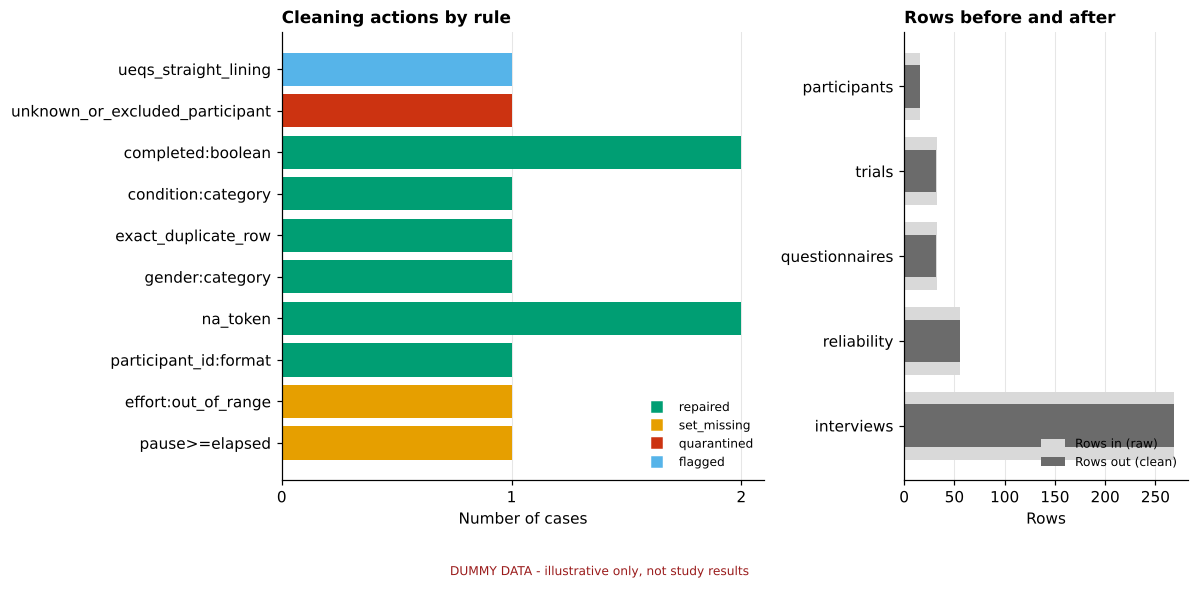

In [4]:
fig = pp.fig_cleaning(clean)
pp.save_fig(fig, "fig_cleaning_summary"); plt.show()

**Every repaired, set-missing and quarantined case** (the audit trail; the full log with flags is exported to `processed/cleaning_log.csv`):

In [5]:
log = clean.log.to_frame()
display(log[log["action"].isin(["repaired", "set_missing", "quarantined"])]
        .drop(columns=["detail"]).reset_index(drop=True))
pp.export_table(summary, "table_cleaning_summary", "Cleaning actions by rule", image=False)

,table,csv_row,participant_id,field,rule,action,original,new
0,participants,17,P16,gender,gender:category,repaired,woman,Woman
1,trials,28,P13,total_map_open_duration_sec,na_token,repaired,n/a,None
2,trials,18,p9,participant_id,participant_id:format,repaired,p9,P09
3,trials,29,P14,completed,completed:boolean,repaired,TRUE,True
4,trials,30,P14,completed,completed:boolean,repaired,No,False
5,trials,23,P11,NaN,exact_duplicate_row,repaired,NaN,None
6,trials,34,P16,elapsed_time_sec;combat_cutscene_pause_sec,pause>=elapsed,set_missing,333.0;353.0,None
7,questionnaires,30,P15,ueqs_item3_raw_1_to_7,na_token,repaired,-,None
8,questionnaires,21,P10,condition,condition:category,repaired,explicit,Explicit
9,questionnaires,25,P12,effort,effort:out_of_range,set_missing,105,None


PosixPath('tables/table_cleaning_summary.csv')

**Quarantined rows** are kept (never deleted) so that each can be checked against the recordings:

In [6]:
for t, q in clean.quarantine.items():
    print(f"{t}: {len(q)} row(s)")
    display(q.drop(columns=["_row"], errors="ignore"))
if not clean.quarantine:
    print("Nothing quarantined.")
if clean.excluded_participants:
    print("Participants excluded for a broken trial design:", clean.excluded_participants)

questionnaires: 1 row(s)


,participant_id,condition,mental_demand,physical_demand,temporal_demand,performance,effort,frustration,ueqs_item1_raw_1_to_7,ueqs_item2_raw_1_to_7,ueqs_item3_raw_1_to_7,ueqs_item4_raw_1_to_7,ueqs_item5_raw_1_to_7,ueqs_item6_raw_1_to_7,ueqs_item7_raw_1_to_7,ueqs_item8_raw_1_to_7,quarantine_reason
0,P17,Explicit,35.0,20.0,30.0,25.0,35.0,15.0,6.0,6.0,5.0,6.0,6.0,5.0,6.0,5.0,unknown_or_excluded_participant


### 2.1 Design integrity
The paper's design crosses condition order with route pairing into four sequences (4 participants each). The check below verifies that every retained participant played **one trial per condition on different routes**,
that the pair forms one of the four sequences, and that the sequences are balanced.

In [7]:
long, wide = pl.prepare(clean)                  # preparation is Section 3; needed here for the sequence label
seq = pl.sequence_table(wide)
display(seq)
print("Design violations found:", clean.excluded_participants or "none")
print("Balanced sequences:", bool((seq['Participants'] == len(wide) / 4).all()))
pp.export_table(seq, "table_sequences", "Counterbalanced sequences", col_widths=[1.4, 3.4, 1.4, 1.0])

,Sequence,Trials,Participants,Target
0,Sequence 1,"R1 explicit, then R2 implicit",4,4
1,Sequence 2,"R2 implicit, then R1 explicit",4,4
2,Sequence 3,"R1 implicit, then R2 explicit",4,4
3,Sequence 4,"R2 explicit, then R1 implicit",4,4


Design violations found: none
Balanced sequences: True


PosixPath('tables/table_sequences.csv')

### 2.2 Outlier flags and remaining missing values

In [8]:
pl.flag_outliers(long, ["completion_time_sec", "wayfinding_errors", "map_openings", "nasa_tlx_raw", "ueqs_overall"], clean.log)
log = clean.log.to_frame()
display(log[(log["action"] == "flagged")].drop(columns=["csv_row"]).reset_index(drop=True))
miss = (long.groupby("condition", observed=True)[list(pl.MEASURES)].apply(lambda g: g.isna().sum()).T
        .rename(columns=lambda c: f"missing, {c}").reset_index().rename(columns={"index": "measure"}))
print("Missing values left in the analysis table (each traced to a logged cleaning action):")
display(miss)

,table,participant_id,field,rule,action,original,new,detail
0,questionnaires,P06,NaN,ueqs_straight_lining,flagged,None,None,all eight UEQ-S items identical
1,analysis_long,P06,completion_time_sec,completion_time_sec:outlier,flagged,480.0,None,Implicit: modified z = 6.1
2,analysis_long,P14,completion_time_sec,completion_time_sec:outlier,flagged,480.0,None,Implicit: modified z = 6.1
3,analysis_long,P06,nasa_tlx_raw,nasa_tlx_raw:outlier,flagged,35.833333,None,Explicit: modified z = 3.7
4,analysis_long,P06,ueqs_overall,ueqs_overall:outlier,flagged,-2.0,None,Implicit: modified z = -4.4


Missing values left in the analysis table (each traced to a logged cleaning action):


condition,measure,"missing, Explicit","missing, Implicit"
0,completion_time_sec,0,1
1,wayfinding_errors,0,0
2,lost_episodes,0,0
3,map_openings,0,0
4,map_open_duration_sec,0,1
5,objective_board_openings,0,0
6,nasa_tlx_raw,1,0
7,ueqs_overall,0,1
8,ueqs_pragmatic,0,1
9,ueqs_hedonic,0,0


## 3. Data preparation
Derived variables follow the paper's definitions exactly (Section *Conditions and measures*).

$$T_{p,m} = \min\Big(t_{\text{end}} - t_{\text{start}} - \sum \text{pauses},\; 480\Big),\qquad T_{p,m}=480 \text{ and not completed if the cap is reached}$$
$$W_{p,m} = \tfrac{1}{6}\sum_{k=1}^{6} s_k \quad (\text{raw NASA-TLX}),\qquad U_{p,m} = \tfrac{1}{8}\sum_{i=1}^{8} (r_i - 4)\ \ (\text{UEQ-S}, -3\ldots{+3}),\ \ \text{pragmatic: items 1-4, hedonic: 5-8}$$
$$\text{error rate} = E_{p,m} / D_{\text{route}},\qquad \text{map time share} = \frac{\text{map open duration}}{T_{p,m}}$$

Two analysis tables are produced:
* **`analysis_long`** - one row per trial (32 rows for 16 participants), for plots and by-condition summaries.
* **`analysis_wide`** - one row per participant with `<measure>_X`, `<measure>_I` and `<measure>_diff` (= I - X) side by side, as stated in the paper.

Unnecessary fields are dropped (raw UEQ-S items after scoring, free-text compass notes after coding, `trial_number` duplicate of `trial_position`, the screening answer that is constant after eligibility filtering). Types are set for analysis: ordered categoricals, nullable integers for counts, booleans.

In [9]:
display(long.head(6))
display(long.dtypes.rename("dtype").to_frame().T)
print("analysis_long :", long.shape, "| analysis_wide :", wide.shape)

,participant_id,condition,route_id,trial_position,active_time_sec,completion_time_sec,completed,timed_out,wayfinding_errors,error_rate,lost_episodes,map_openings,map_open_duration_sec,map_time_share,objective_board_openings,compass_use,mental_demand,physical_demand,temporal_demand,performance,effort,frustration,nasa_tlx_raw,ueqs_pragmatic,ueqs_hedonic,ueqs_overall,age,gender,weekly_gaming_hours,years_of_gaming,open_world_game_experience,previous_assassins_creed_play,input_device,sequence
0,P01,Explicit,Route_A,1,180.0,180.0,True,False,1,0.25,0,2,38.0,0.211111,1,1,35.0,20.0,30.0,25.0,35.0,15.0,26.666667,1.75,1.50,1.625,21,Woman,8.0,4.0,True,False,Keyboard and mouse,1
1,P01,Implicit,Route_B,2,260.0,260.0,True,False,3,0.75,2,5,104.0,0.400000,4,2,65.0,30.0,60.0,55.0,70.0,50.0,55.000000,-0.25,-0.50,-0.375,21,Woman,8.0,4.0,True,False,Keyboard and mouse,1
2,P02,Implicit,Route_A,1,270.0,270.0,True,False,2,0.50,1,5,115.0,0.425926,3,3,55.0,25.0,50.0,45.0,55.0,35.0,44.166667,0.25,0.50,0.375,22,Man,12.0,6.0,True,True,Gamepad,3
3,P02,Explicit,Route_B,2,205.0,205.0,True,False,0,0.00,0,2,31.0,0.151220,1,1,30.0,20.0,25.0,30.0,30.0,15.0,25.000000,1.75,1.75,1.750,22,Man,12.0,6.0,True,True,Gamepad,3
4,P03,Explicit,Route_B,1,170.0,170.0,True,False,0,0.00,0,1,19.0,0.111765,1,3,25.0,15.0,20.0,25.0,25.0,10.0,20.000000,1.75,1.75,1.750,20,Woman,5.0,3.0,True,False,Keyboard and mouse,4
5,P03,Implicit,Route_A,2,250.0,250.0,True,False,2,0.50,1,4,92.0,0.368000,3,2,50.0,25.0,45.0,40.0,50.0,30.0,40.000000,-0.25,-0.25,-0.250,20,Woman,5.0,3.0,True,False,Keyboard and mouse,4


,participant_id,condition,route_id,trial_position,active_time_sec,completion_time_sec,completed,timed_out,wayfinding_errors,error_rate,lost_episodes,map_openings,map_open_duration_sec,map_time_share,objective_board_openings,compass_use,mental_demand,physical_demand,temporal_demand,performance,effort,frustration,nasa_tlx_raw,ueqs_pragmatic,ueqs_hedonic,ueqs_overall,age,gender,weekly_gaming_hours,years_of_gaming,open_world_game_experience,previous_assassins_creed_play,input_device,sequence
dtype,str,category,category,Int64,float64,float64,boolean,bool,Int64,float64,Int64,Int64,float64,float64,Int64,Int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,Int64,category,float64,float64,boolean,boolean,category,Int64


analysis_long : (32, 34) | analysis_wide : (16, 72)


In [10]:
DICT = [
 ("participant_id", "Anonymous ID (P01...)", "-", "text"),
 ("condition", "Guidance condition: Explicit = Guided Exploration on (X), Implicit = off (I)", "-", "ordered category"),
 ("route_id", "Route played (Route_A = R1, Route_B = R2)", "-", "ordered category"),
 ("trial_position", "Order of the trial in the session (1 or 2)", "-", "integer"),
 ("active_time_sec", "Elapsed time minus combat and cutscene pauses", "s", "float"),
 ("completion_time_sec", "T: active time capped at 480 s; not-completed trials = 480", "s", "float"),
 ("completed", "Objective reached before the cap", "-", "boolean"),
 ("timed_out", "Not completed (cap reached)", "-", "boolean"),
 ("wayfinding_errors", "E: wrong branches entered and stayed on > 10 s, 0 <= E <= D", "count", "integer"),
 ("error_rate", "E divided by the route's decision points D", "proportion", "float"),
 ("lost_episodes", "L: periods of not knowing where to go (interview + recording)", "count", "integer"),
 ("map_openings", "Number of map openings coded from recording", "count", "integer"),
 ("map_open_duration_sec", "Total time the map was open", "s", "float"),
 ("map_time_share", "Map open duration divided by completion time", "proportion", "float"),
 ("objective_board_openings", "Objective-board / quest-log openings", "count", "integer"),
 ("compass_use", "Interview-coded compass use: 0 none, 1 brief, 2 frequent, 3 relied on", "ordinal 0-3", "integer"),
 ("mental_demand", "NASA-TLX subscale", "0-100", "float"),
 ("physical_demand", "NASA-TLX subscale", "0-100", "float"),
 ("temporal_demand", "NASA-TLX subscale", "0-100", "float"),
 ("performance", "NASA-TLX subscale (0 = perfect, 100 = failure)", "0-100", "float"),
 ("effort", "NASA-TLX subscale", "0-100", "float"),
 ("frustration", "NASA-TLX subscale", "0-100", "float"),
 ("nasa_tlx_raw", "W: unweighted mean of the six subscales", "0-100", "float"),
 ("ueqs_pragmatic", "UEQ-S items 1-4, scored -3...+3", "-3 to +3", "float"),
 ("ueqs_hedonic", "UEQ-S items 5-8, scored -3...+3", "-3 to +3", "float"),
 ("ueqs_overall", "UEQ-S mean of all eight items", "-3 to +3", "float"),
 ("age", "Participant age", "years", "integer"),
 ("gender", "Self-reported gender", "-", "category"),
 ("weekly_gaming_hours", "Gaming hours per week", "hours", "float"),
 ("years_of_gaming", "Years of playing games", "years", "float"),
 ("open_world_game_experience", "Has open-world game experience", "-", "boolean"),
 ("previous_assassins_creed_play", "Has played another Assassin's Creed game", "-", "boolean"),
 ("input_device", "Keyboard and mouse or gamepad (fixed per participant)", "-", "category"),
 ("sequence", "Counterbalanced sequence 1-4 (from trial 1's condition and route)", "-", "integer"),
]
data_dictionary = pd.DataFrame(DICT, columns=["field", "definition", "unit", "type"])
undocumented = set(long.columns) - set(data_dictionary["field"])
assert not undocumented, f"undocumented fields: {undocumented}"
data_dictionary["dtype in table"] = data_dictionary["field"].map(lambda f: str(long[f].dtype))
display(data_dictionary)
pp.export_table(data_dictionary, "table_data_dictionary", "Data dictionary: analysis_long", image=False)

,field,definition,unit,type,dtype in table
0,participant_id,Anonymous ID (P01...),-,text,str
1,condition,"Guidance condition: Explicit = Guided Exploration on (X), Implicit = off (I)",-,ordered category,category
2,route_id,"Route played (Route_A = R1, Route_B = R2)",-,ordered category,category
3,trial_position,Order of the trial in the session (1 or 2),-,integer,Int64
4,active_time_sec,Elapsed time minus combat and cutscene pauses,s,float,float64
5,completion_time_sec,T: active time capped at 480 s; not-completed trials = 480,s,float,float64
6,completed,Objective reached before the cap,-,boolean,boolean
7,timed_out,Not completed (cap reached),-,boolean,bool
8,wayfinding_errors,"E: wrong branches entered and stayed on > 10 s, 0 <= E <= D",count,integer,Int64
9,error_rate,E divided by the route's decision points D,proportion,float,float64


PosixPath('tables/table_data_dictionary.csv')

## 4. Participants and design

In [11]:
parts_tbl = pl.participant_table(clean.participants)
display(parts_tbl)
pp.export_table(parts_tbl, "table_participants", "Table 1. Participant characteristics", col_widths=[2.2, 6.4], wrap=70)

,Characteristic,Summary
0,Participants (n),16
1,Age (years),"median 22 [20, 25]; mean 22.2 (SD 1.8)"
2,Gender,Woman: 8 (50%); Man: 7 (44%); Non-binary: 1 (6%)
3,Gaming hours per week,"median 8.5 [4, 15]; mean 8.2 (SD 3.5)"
4,Years of gaming,"median 5 [2, 9]; mean 4.9 (SD 2.2)"
5,Open-world experience,Yes: 15 (94%); No: 1 (6%)
6,Prior Assassin's Creed play,No: 9 (56%); Yes: 7 (44%)
7,Input device,Gamepad: 9 (56%); Keyboard and mouse: 7 (44%)


PosixPath('tables/table_participants.csv')

## 5. Results
Per the analysis plan, **Step 1** reports for each measure the median and range per condition ($n=16$), mean and SD, and the number of participants whose value is higher under X, higher under I, or equal.
Paired plots show every participant. RQ1 is answered from the literature (paper, Sections *Forms of guidance* and *Measures*) and needs no data.
Conditions: **X** = more explicit (Guided Exploration on), **I** = more implicit (off).

### 5.1 RQ2 - Which information sources do players use, and how?
Measures: map openings, map open duration, objective-board openings (coded from recordings); compass use (interview-coded); interview codes for information sources (GQ1).

,Measure,"X median [min, max]",X mean (SD),"I median [min, max]",I mean (SD),Higher under X / I / equal (n),Pairs (n)
0,Map openings (count),"2 [1, 4]",2.2 (0.9),"5.5 [4, 8]",5.7 (1.4),0 / 16 / 0,16
1,Map open duration (s),"40 [19, 65]",40.4 (14.6),"112 [92, 190]",121.7 (29.8),0 / 15 / 0,15
2,Objective-board openings (count),"1 [1, 2]",1.2 (0.4),"3.5 [2, 6]",3.8 (1.1),0 / 15 / 1,16


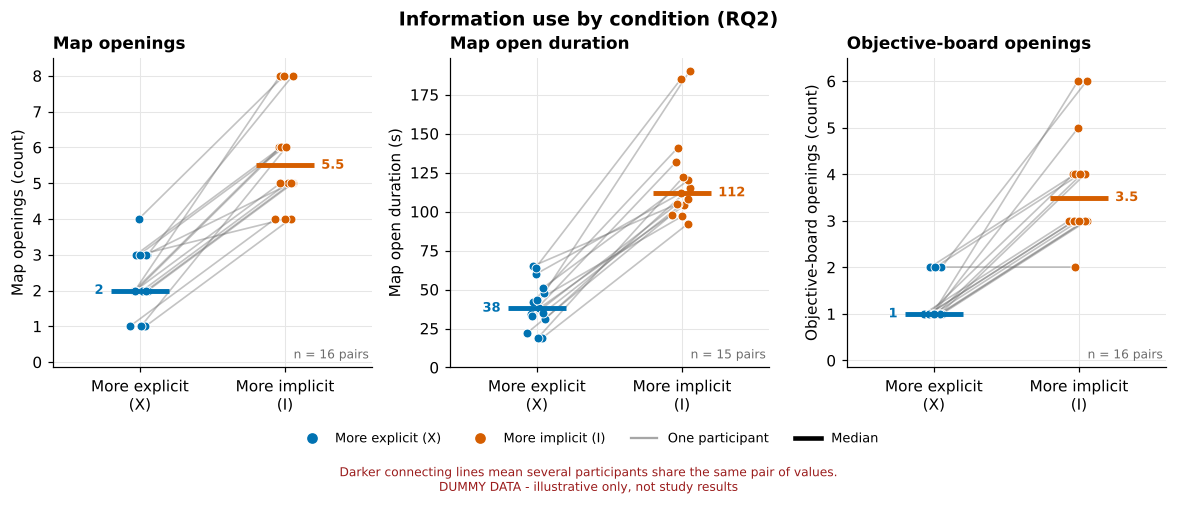

In [12]:
rq2 = pl.describe_by_condition(long, wide, pl.RQ_MEASURES["RQ2"])
t_rq2 = pl.format_descriptives(rq2)
display(t_rq2)
pp.export_table(t_rq2, "table_rq2_information_use", "Table 2. Information use by condition (RQ2)",
                col_widths=[2.4, 1.8, 1.4, 1.8, 1.4, 2.0, 0.9], note="X = more explicit, I = more implicit.")
fig = pp.fig_paired(wide, pl.RQ_MEASURES["RQ2"], "Information use by condition (RQ2)")
pp.save_fig(fig, "fig_rq2_information_use"); plt.show()

In [13]:
share = pl.describe_by_condition(long, wide, ["map_time_share"])
print("Share of the trial spent with the map open (proportion of completion time):")
display(share[["label", "median_X", "min_X", "max_X", "median_I", "min_I", "max_I"]].round(3))

comp = (long.assign(compass=long["compass_use"].map(pl.COMPASS_LABELS))
        .pivot_table(index="compass", columns="condition", values="participant_id", aggfunc="count", observed=False, fill_value=0)
        .reindex(list(pl.COMPASS_LABELS.values())).fillna(0).astype(int).reset_index())
comp.columns = ["Compass use (interview-coded)", "X (trials)", "I (trials)"]
display(comp)
pp.export_table(comp, "table_rq2_compass", "Compass use, coded from interview notes", col_widths=[3, 1.4, 1.4], font=10)

Share of the trial spent with the map open (proportion of completion time):


,label,median_X,min_X,max_X,median_I,min_I,max_I
0,map_time_share,0.198,0.111,0.37,0.391,0.307,0.47


,Compass use (interview-coded),X (trials),I (trials)
0,None,0,0
1,Brief,9,0
2,Frequent,0,6
3,Relied on,7,10


PosixPath('tables/table_rq2_compass.csv')

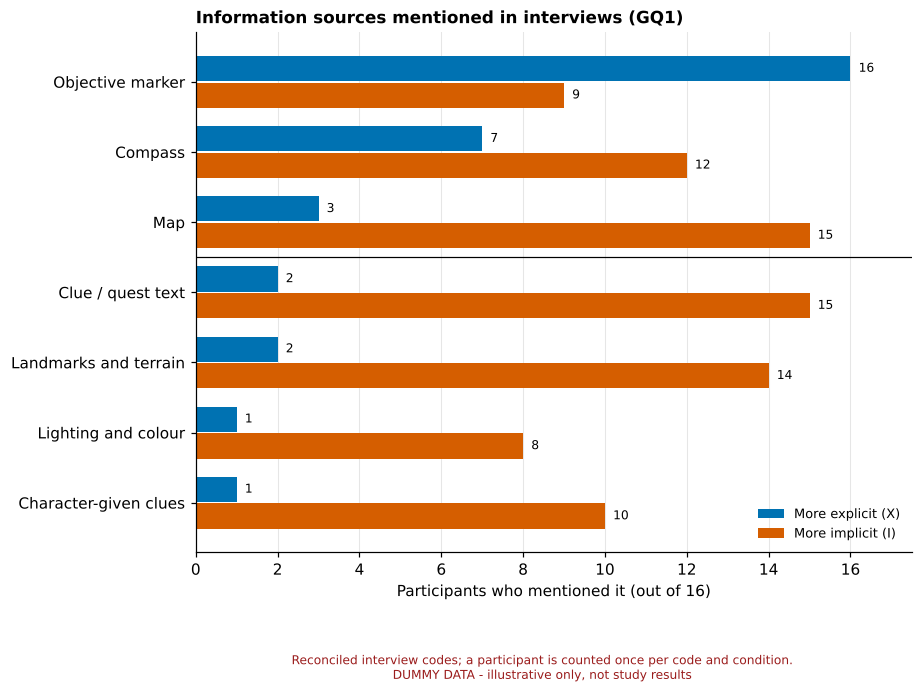

In [14]:
interviews = clean.tables["interviews"]
counts = pl.code_participant_counts(interviews, len(clean.participants))
src_codes = [c for c, v in pl.CODEBOOK.items() if v[0] == "source"]
fig = pp.fig_code_counts(counts, src_codes, "Information sources mentioned in interviews (GQ1)", len(clean.participants))
pp.save_fig(fig, "fig_rq2_sources_interviews"); plt.show()

### 5.2 RQ3 - How does wayfinding behaviour look, and what explains it?
Measures: completion time $T$ (capped at 480 s), wayfinding errors $E$, lost episodes $L$, completion count and timeouts.

In [15]:
rq3 = pl.describe_by_condition(long, wide, pl.RQ_MEASURES["RQ3"])
t_rq3 = pl.format_descriptives(rq3)
display(t_rq3)
pp.export_table(t_rq3, "table_rq3_wayfinding", "Table 3. Wayfinding behaviour by condition (RQ3)",
                col_widths=[2.4, 1.8, 1.4, 1.8, 1.4, 2.0, 0.9], note="X = more explicit, I = more implicit. Not-completed trials count as 480 s.")
ct = pl.completion_table(long)
display(ct)
pp.export_table(ct, "table_rq3_completion", "Completion and timeouts per condition", col_widths=[1.6, 1.0, 1.2, 1.2, 1.8], font=10)

,Measure,"X median [min, max]",X mean (SD),"I median [min, max]",I mean (SD),Higher under X / I / equal (n),Pairs (n)
0,Completion time (s),"194.5 [168, 227]",193.4 (19.9),"290 [221, 480]",308.7 (75.5),1 / 14 / 0,15
1,Wayfinding errors (count),"1 [0, 3]",0.8 (0.8),"2.5 [1, 4]",2.6 (0.8),1 / 15 / 0,16
2,Lost episodes (count),"0 [0, 1]",0.1 (0.3),"1 [1, 3]",1.6 (0.7),0 / 14 / 2,16


,condition,trials,completed,timeouts,completion_rate_pct
0,Explicit,16,16,0,100.0
1,Implicit,16,14,2,87.5


PosixPath('tables/table_rq3_completion.csv')

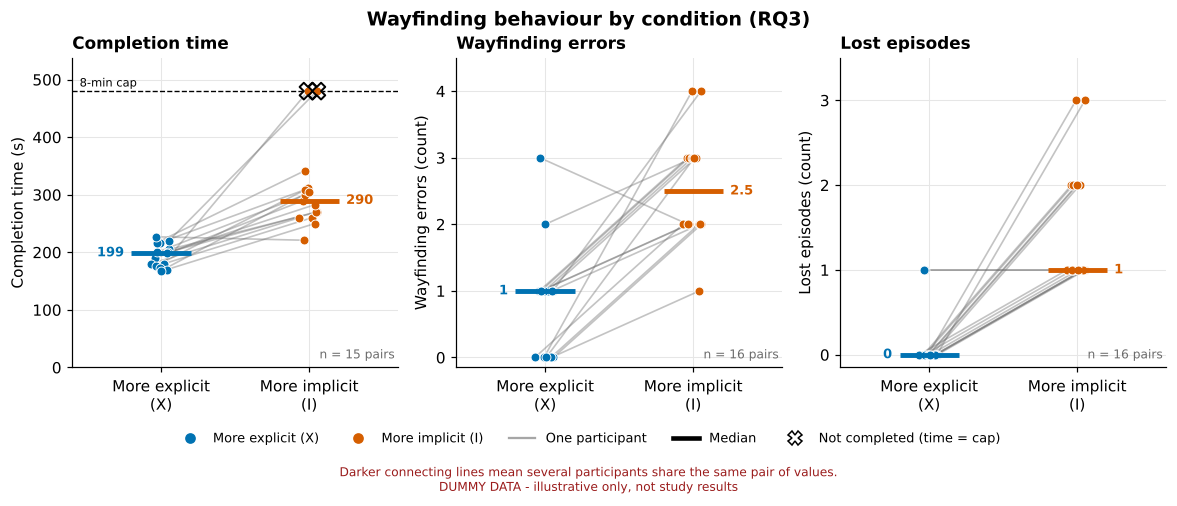

In [16]:
fig = pp.fig_paired(wide, pl.RQ_MEASURES["RQ3"], "Wayfinding behaviour by condition (RQ3)", long=long, cap_line=True)
pp.save_fig(fig, "fig_rq3_wayfinding"); plt.show()

In [17]:
er = pl.describe_by_condition(long, wide, ["error_rate"])
print("Errors per decision point (route-normalised):")
display(er[["label", "median_X", "min_X", "max_X", "median_I", "min_I", "max_I", "n_higher_X", "n_higher_I", "n_equal"]].round(2))

Errors per decision point (route-normalised):


,label,median_X,min_X,max_X,median_I,min_I,max_I,n_higher_X,n_higher_I,n_equal
0,error_rate,0.25,0.0,0.75,0.62,0.25,1.0,1,15,0


### 5.3 RQ4 - How do players describe workload, difficulty and experience?
Measures: raw NASA-TLX (overall and six subscales) and UEQ-S (overall, pragmatic, hedonic).

,Measure,"X median [min, max]",X mean (SD),"I median [min, max]",I mean (SD),Higher under X / I / equal (n),Pairs (n)
0,NASA-TLX (raw) (0-100),"26.7 [19.2, 35.8]",26.6 (4.3),"53.8 [40, 75.8]",54.4 (8.7),0 / 15 / 0,15
1,UEQ-S overall (-3 to +3),"1.6 [0.8, 1.9]",1.5 (0.4),"-0.4 [-2, 0.4]",-0.5 (0.6),15 / 0 / 0,15
2,UEQ-S pragmatic (-3 to +3),"1.8 [0.8, 2]",1.5 (0.4),"-0.2 [-2, 0.2]",-0.5 (0.6),15 / 0 / 0,15
3,UEQ-S hedonic (-3 to +3),"1.8 [0.8, 2.2]",1.6 (0.4),"-0.6 [-2, 0.5]",-0.6 (0.6),16 / 0 / 0,16


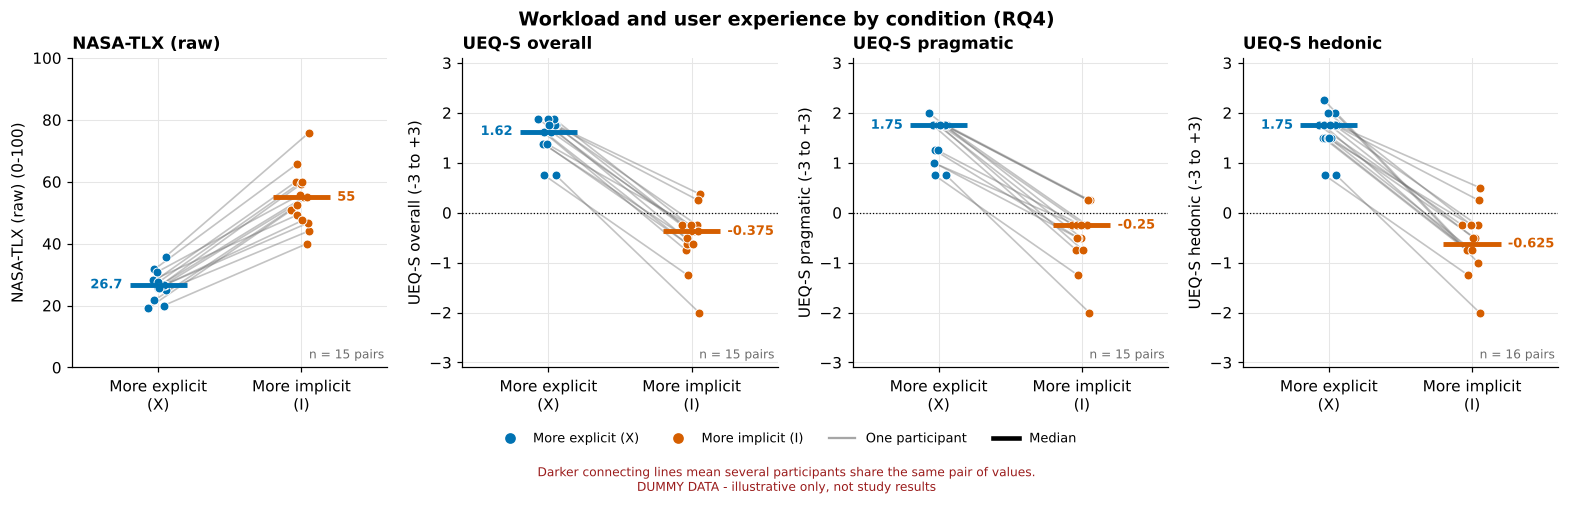

In [18]:
rq4 = pl.describe_by_condition(long, wide, pl.RQ_MEASURES["RQ4"])
t_rq4 = pl.format_descriptives(rq4)
display(t_rq4)
pp.export_table(t_rq4, "table_rq4_workload_experience", "Table 4. Workload and user experience by condition (RQ4)",
                col_widths=[2.4, 1.8, 1.4, 1.8, 1.4, 2.0, 0.9], note="X = more explicit, I = more implicit. UEQ-S scored -3 to +3.")
fig = pp.fig_paired(wide, pl.RQ_MEASURES["RQ4"], "Workload and user experience by condition (RQ4)", ncols=4)
pp.save_fig(fig, "fig_rq4_workload_experience"); plt.show()

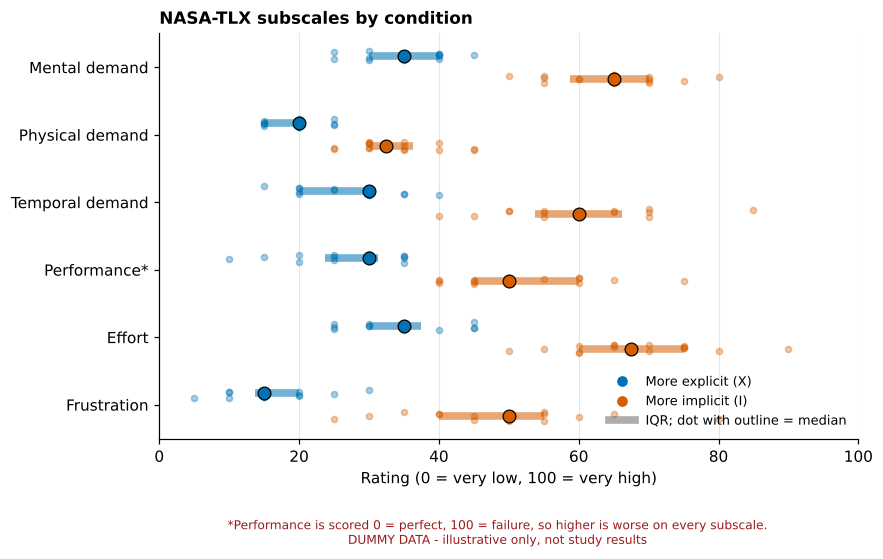

,Measure,"X median [min, max]",X mean (SD),"I median [min, max]",I mean (SD),Higher under X / I / equal (n),Pairs (n)
0,mental_demand (0-100),"35 [25, 45]",35 (5.8),"65 [50, 80]",64.4 (8.1),0 / 16 / 0,16
1,physical_demand (0-100),"20 [15, 25]",19.4 (3.6),"32.5 [25, 45]",33.8 (6.2),0 / 16 / 0,16
2,temporal_demand (0-100),"30 [15, 40]",27.2 (6.8),"60 [40, 85]",59.7 (11.2),0 / 16 / 0,16
3,performance (0-100),"30 [10, 35]",26.9 (7.5),"50 [40, 75]",51.6 (10.1),0 / 16 / 0,16
4,effort (0-100),"35 [25, 45]",34.3 (7),"67.5 [50, 90]",68.1 (10.1),0 / 15 / 0,15
5,frustration (0-100),"15 [5, 30]",15.9 (6.1),"50 [25, 80]",48.8 (13.6),0 / 16 / 0,16


PosixPath('tables/table_rq4_tlx_subscales.csv')

In [19]:
fig = pp.fig_tlx_subscales(long)
pp.save_fig(fig, "fig_rq4_tlx_subscales"); plt.show()
sub = pl.describe_by_condition(long, wide, pl.TLX_COLS)
sub["label"] = sub["label"].str.replace("Performance", "Performance*")
t_sub = pl.format_descriptives(sub.assign(unit="0-100"))
display(t_sub)
pp.export_table(t_sub, "table_rq4_tlx_subscales", "NASA-TLX subscales by condition", col_widths=[2.4, 1.8, 1.4, 1.8, 1.4, 2.0, 0.9],
                note="*Performance: 0 = perfect, 100 = failure.")

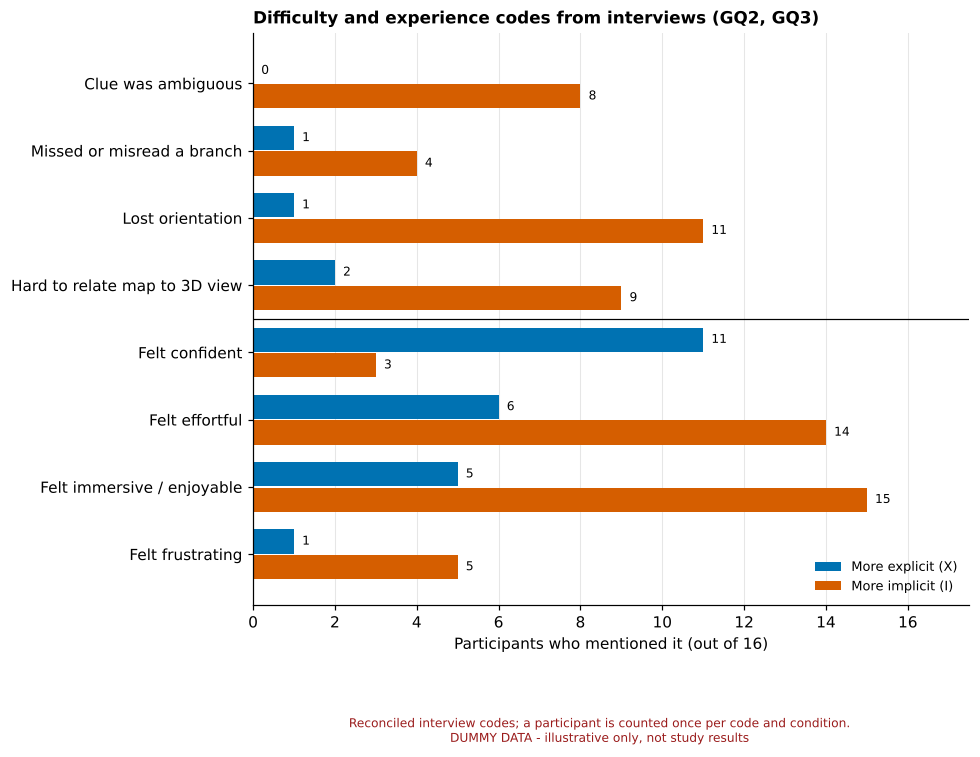

In [20]:
inter = [c for c, v in pl.CODEBOOK.items() if v[0] in ("difficulty", "experience")]
fig = pp.fig_code_counts(counts, inter, "Difficulty and experience codes from interviews (GQ2, GQ3)", len(clean.participants))
pp.save_fig(fig, "fig_rq4_interview_codes"); plt.show()

### 5.4 Size and consistency of within-participant differences
Because each participant is their own comparison, the difference $D_p = \text{value}(I) - \text{value}(X)$ is the natural unit. We report it as **estimation**: median and mean difference,
a percentile **bootstrap 95% interval** for the mean (10,000 resamples, fixed seed) and the paired standardised effect $d_z$. These describe the sample; they are not significance tests and carry no causal claim.

,Measure,Pairs,Median I-X,Mean I-X,95% CI low,95% CI high,d_z
0,Completion time,15,94.00,113.80,79.87,154.00,1.47
1,Wayfinding errors,16,2.00,1.75,1.19,2.25,1.55
2,Lost episodes,16,1.00,1.44,1.00,1.88,1.61
3,Map openings,16,3.00,3.44,2.88,4.00,2.84
4,Map open duration,15,73.00,81.47,68.73,95.20,3.01
5,Objective-board openings,16,2.00,2.50,1.94,3.06,2.17
6,NASA-TLX (raw),15,28.33,27.89,24.83,31.06,4.34
7,UEQ-S overall,15,-2.00,-2.05,-2.22,-1.88,-5.71
8,UEQ-S pragmatic,15,-2.00,-1.92,-2.15,-1.70,-4.17
9,UEQ-S hedonic,16,-2.25,-2.19,-2.42,-1.95,-4.57


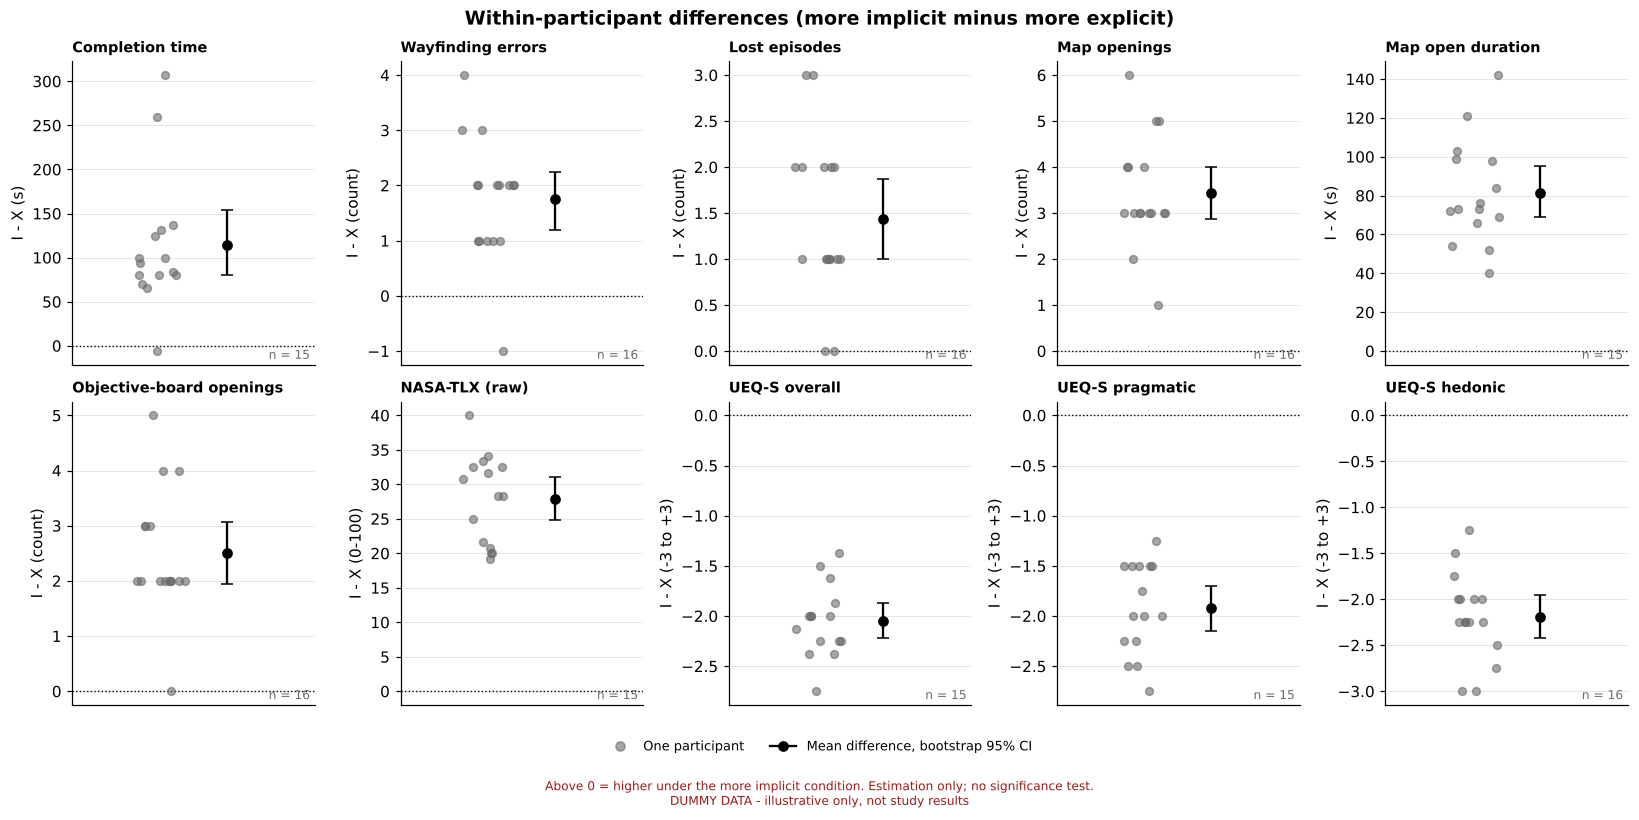

In [21]:
all_measures = list(pl.MEASURES)
diffs = pl.paired_differences(wide, all_measures, n_boot=10_000, seed=SEED)
t_diff = diffs.assign(**{c: diffs[c].round(2) for c in ["median_diff", "mean_diff", "ci95_low", "ci95_high", "dz"]})
t_diff = t_diff.rename(columns={"label": "Measure", "n_pairs": "Pairs", "median_diff": "Median I-X", "mean_diff": "Mean I-X",
                                "ci95_low": "95% CI low", "ci95_high": "95% CI high", "dz": "d_z"}).drop(columns="measure")
display(t_diff)
pp.export_table(t_diff, "table_paired_differences", "Table 5. Within-participant differences (I minus X)", col_widths=[2.6, 0.8, 1.2, 1.2, 1.2, 1.2, 0.9],
                note="Bootstrap interval for the mean difference; descriptive estimation, not a significance test.")
fig = pp.fig_differences(wide, all_measures, diffs)
pp.save_fig(fig, "fig_paired_differences"); plt.show()

In [22]:
if RUN_EXPLORATORY_TESTS:
    # NOT part of the paper's analysis plan. Reported only if the plan is amended.
    wx = pl.exploratory_wilcoxon(wide, all_measures)
    display(wx.round(4))
else:
    print("Exploratory Wilcoxon tests are OFF (RUN_EXPLORATORY_TESTS = False): the paper commits to descriptive analysis only.\n"
          "To use them, amend the Analysis plan first, then switch the flag on; Holm correction is applied (pl.exploratory_wilcoxon).")

Exploratory Wilcoxon tests are OFF (RUN_EXPLORATORY_TESTS = False): the paper commits to descriptive analysis only.
To use them, amend the Analysis plan first, then switch the flag on; Holm correction is applied (pl.exploratory_wilcoxon).


### 5.5 Trial position and route (learning and route checks)
The paper reports results "by trial position and route, descriptively". Counterbalancing puts each condition in each position and on each route equally often, so any learning or route effect is spread across conditions; the table and figure show how large it looks.

By trial position (median [min, max])


,condition,trial_position,n,completion_time_sec,wayfinding_errors,lost_episodes
0,Explicit,1,8,"180 [170, 227]","0 [0, 3]","0 [0, 1]"
1,Explicit,2,8,"202.5 [168, 220]","1 [0, 2]","0 [0, 1]"
2,Implicit,1,8,"306.5 [270, 480]","2.5 [2, 4]","1.5 [1, 3]"
3,Implicit,2,8,"260 [221, 480]","2.5 [1, 4]","1 [1, 3]"


By route (median [min, max])


,condition,route_id,n,completion_time_sec,wayfinding_errors,lost_episodes
0,Explicit,Route_A,8,"185 [168, 217]","1 [0, 2]","0 [0, 1]"
1,Explicit,Route_B,8,"202 [170, 227]","0.5 [0, 3]","0 [0, 1]"
2,Implicit,Route_A,8,"276.5 [221, 480]","2 [1, 4]","1 [1, 3]"
3,Implicit,Route_B,8,"300 [260, 480]","3 [2, 4]","2 [1, 3]"


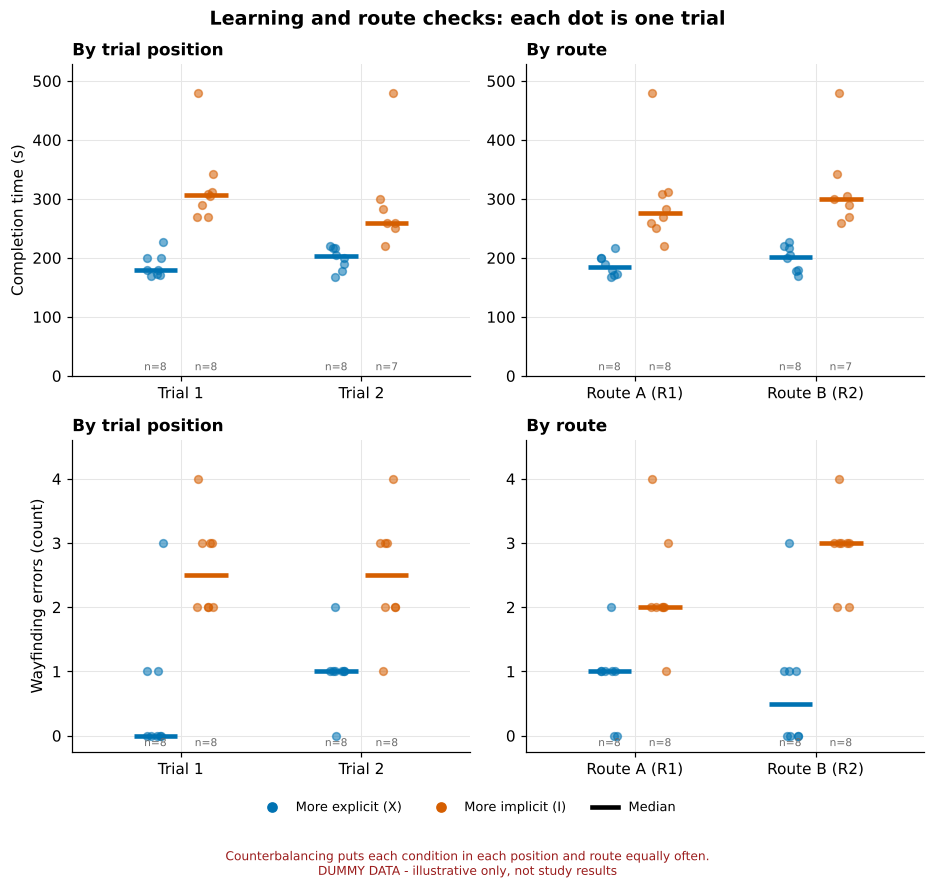

In [23]:
cols = ["completion_time_sec", "wayfinding_errors", "lost_episodes"]
by_pos = pl.describe_by_group(long, "trial_position", cols)
by_route = pl.describe_by_group(long, "route_id", cols)
for name, t in (("By trial position (median [min, max])", by_pos), ("By route (median [min, max])", by_route)):
    print(name); display(t)
nice = {"completion_time_sec": "Completion time (s)", "wayfinding_errors": "Errors", "lost_episodes": "Lost episodes"}
pp.export_table(by_pos.rename(columns=nice), "table_by_trial_position", "Median [min, max] by trial position and condition", col_widths=[1.2, 1.3, 0.6, 2.0, 1.6, 1.8], font=9)
pp.export_table(by_route.rename(columns=nice), "table_by_route", "Median [min, max] by route and condition", col_widths=[1.2, 1.3, 0.6, 2.0, 1.6, 1.8], font=9)
fig = pp.fig_order_route(long)
pp.save_fig(fig, "fig_order_route"); plt.show()

### 5.6 Individual cases and covariates
Covariates (experience, device) are used **to describe participants and read individual cases, not to adjust the measures** (paper, *Recorded covariates*).
We list participants whose pattern differs from the majority, and show the I - X difference next to experience. Spearman $\rho$ is given without a p-value.

,measure,participant_id,difference_I_minus_X,direction
0,Completion time,P13,-6.0,higher under X
1,Wayfinding errors,P13,-1.0,higher under X


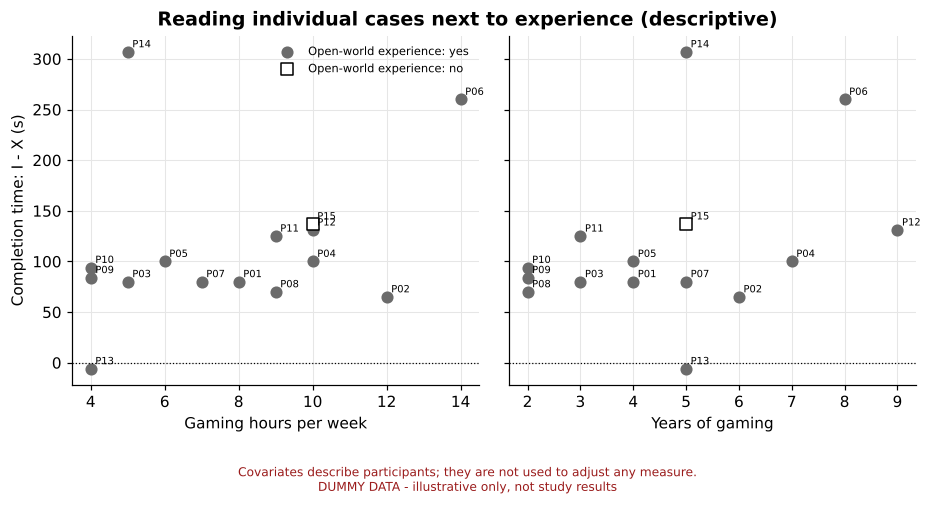

,measure,covariate,n,spearman_rho
0,Completion time,weekly_gaming_hours,15,0.29
1,Completion time,years_of_gaming,15,0.32
2,Wayfinding errors,weekly_gaming_hours,16,0.26
3,Wayfinding errors,years_of_gaming,16,0.32
4,NASA-TLX (raw),weekly_gaming_hours,15,0.04
5,NASA-TLX (raw),years_of_gaming,15,0.11


In [24]:
cc = pl.counter_cases(wide, ["completion_time_sec", "wayfinding_errors", "nasa_tlx_raw", "ueqs_overall"])
display(cc)
pp.export_table(cc.round(2), "table_counter_cases", "Participants not following the majority direction", image=False)
fig = pp.fig_covariates(wide)
pp.save_fig(fig, "fig_covariates"); plt.show()
cov = pl.covariate_table(wide, ["completion_time_sec", "wayfinding_errors", "nasa_tlx_raw"], ["weekly_gaming_hours", "years_of_gaming"])
display(cov.round(2))

### 5.7 Interviews: thematic analysis (Analysis plan, Step 2)
Two researchers independently code the transcripts following Braun and Clarke's phases; codes start from the two groups of information sources in the paper (external aids; environment and narrative) and are extended with emergent codes. The table below is the **codebook** with how many participants mentioned each code under each condition. Excerpts in the dummy file are placeholders.

In [25]:
cb = counts.copy()
cb["Group"] = cb["group"]; cb["Code"] = cb["label"]
cb["Participants X / I"] = cb["participants_X"].astype(str) + " / " + cb["participants_I"].astype(str)
cb["Segments X / I"] = cb["segments_X"].astype(str) + " / " + cb["segments_I"].astype(str)
cb = cb.sort_values(["family", "Group", "participants_I"], ascending=[True, True, False])[["Group", "Code", "Participants X / I", "Segments X / I"]]
display(cb)
pp.export_table(cb, "table_codebook_counts", f"Interview codes (n = {len(clean.participants)} participants)", col_widths=[2.6, 3.0, 1.8, 1.6], font=9)
themes = pl.theme_participants(interviews)
t_themes = themes.assign(**{"Participants X / I": themes["participants_X"].astype(str) + " / " + themes["participants_I"].astype(str),
                            "Segments X / I": themes["segments_X"].astype(str) + " / " + themes["segments_I"].astype(str)})[["Theme", "Codes", "Participants X / I", "Segments X / I"]]
display(t_themes)
pp.export_table(t_themes, "table_themes", "Candidate themes (placeholders until coding is finished)", col_widths=[3.0, 3.6, 1.6, 1.5], wrap=46, font=9)

,Group,Code,Participants X / I,Segments X / I
7,Wayfinding difficulty,Lost orientation,1 / 11,1 / 11
9,Wayfinding difficulty,Hard to relate map to 3D view,2 / 9,2 / 9
0,Wayfinding difficulty,Clue was ambiguous,0 / 8,0 / 8
11,Wayfinding difficulty,Missed or misread a branch,1 / 4,1 / 4
14,Experience,Felt immersive / enjoyable,5 / 15,5 / 15
13,Experience,Felt effortful,6 / 14,6 / 14
4,Experience,Felt frustrating,1 / 5,1 / 5
12,Experience,Felt confident,11 / 3,11 / 3
2,Environment and narrative,Clue / quest text,2 / 15,4 / 20
5,Environment and narrative,Landmarks and terrain,2 / 14,3 / 20


,Theme,Codes,Participants X / I,Segments X / I
0,Marker-led following,"marker, more_confident",16 / 10,38 / 16
1,Interpreting clues with the environment,"clue_text, landmarks_terrain, lighting_colour, character_clues",6 / 16,11 / 65
2,Map and compass as fallback,"map, compass, map_hard_to_relate",10 / 16,19 / 49
3,Getting lost and recovering,"ambiguous_clue, missed_branch, lost_orientation",2 / 16,2 / 23
4,Effort versus immersion,"more_effortful, more_immersive, frustrating",9 / 16,12 / 34


PosixPath('tables/table_themes.csv')

### 5.8 Integration (Analysis plan, Step 3)
For each of RQ2 to RQ4: the descriptive pattern, the supporting or contradicting interview themes, and the related work. A pattern with no coded theme is reported as **unexplained**; an interview theme with no counterpart in the numbers would be reported the same way.

In [26]:
desc_all = pl.describe_by_condition(long, wide, all_measures)
jd = pl.joint_display(desc_all, themes)
for _, r in jd.iterrows():
    print(f"=== {r['RQ']} ===\nPattern:\n  " + r["Descriptive pattern"].replace("\n", "\n  ") +
          "\nThemes:\n  " + r["Interview themes"].replace("\n", "\n  ") + "\nRelated work:\n  " + r["Related work"] + "\n")
pp.export_table(jd, "table_joint_display", "Table 6. Integration of numbers, interview themes and related work",
                col_widths=[0.6, 4.4, 3.6, 3.6], wrap=52, font=8)

=== RQ2 ===
Pattern:
  Map openings: median 2 (X) vs 5.5 (I); higher under I in 16/16
  Map open duration: median 40 (X) vs 112 (I); higher under I in 15/15
  Objective-board openings: median 1 (X) vs 3.5 (I); higher under I in 15/16
Themes:
  Marker-led following: 16 (X) / 10 (I) participants
  Interpreting clues with the environment: 6 (X) / 16 (I) participants
  Map and compass as fallback: 10 (X) / 16 (I) participants
Related work:
  Xiao (2020): HUD aids vs. cues built into the environment; reading a map means relating it to the 3D view. Moura & Bartram (2014): responses to cues depend on game context.

=== RQ3 ===
Pattern:
  Completion time: median 194.5 (X) vs 290 (I); higher under I in 14/15
  Wayfinding errors: median 1 (X) vs 2.5 (I); higher under I in 15/16
  Lost episodes: median 0 (X) vs 1 (I); higher under I in 14/16
Themes:
  Getting lost and recovering: 2 (X) / 16 (I) participants
  Interpreting clues with the environment: 6 (X) / 16 (I) participants
Related work:
  Lan

PosixPath('tables/table_joint_display.csv')

### 5.9 Coder reliability
One researcher codes all recordings; a second independently codes a random quarter of the participants. Agreement on the per-decision-point **error code** is reported with **Cohen's kappa**; the other counts with **percent agreement** (paper, *Coding and data handling*).
Coder 1's values are also checked against the trials table so the two files cannot drift apart.

Double-coded participants: 4 of 16 (target: a quarter = 4) -> ['P04', 'P07', 'P08', 'P11']
Coder 1 differs from trials table: none


,measure,method,units,value,percent_agreement,within_1_pct,mean_abs_diff,kappa_label
0,Wayfinding error code (per decision point),Cohen's kappa,32,0.93,96.9,NaN,NaN,almost perfect
1,Lost episodes (per trial count),Exact % agreement,8,NaN,75.0,100.0,0.25,
2,Map openings (per trial count),Exact % agreement,8,NaN,75.0,100.0,0.25,
3,Objective board openings (per trial count),Exact % agreement,8,NaN,50.0,100.0,0.50,


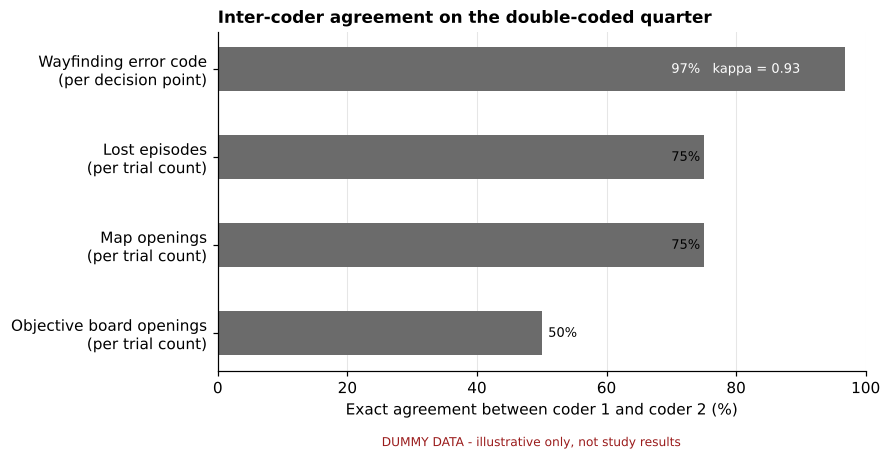

In [27]:
rel = clean.tables["reliability"]
n_double = rel["participant_id"].nunique()
print(f"Double-coded participants: {n_double} of {len(clean.participants)} (target: a quarter = {len(clean.participants)//4}) -> {sorted(rel['participant_id'].unique())}")
mismatch = pl.reliability_consistency(rel, clean.trials, clean.log)
print("Coder 1 differs from trials table:", "none" if mismatch.empty else mismatch.to_dict("records"))
rs = pl.reliability_summary(rel)
show = rs.assign(value=rs["value"].round(2), percent_agreement=rs["percent_agreement"].round(1),
                 within_1_pct=rs["within_1_pct"].round(1), mean_abs_diff=rs["mean_abs_diff"].round(2))
display(show)
pp.export_table(show.fillna(""), "table_reliability", "Table 7. Inter-coder agreement", col_widths=[3.6, 1.6, 0.7, 0.8, 1.2, 1.0, 1.0, 1.4], wrap=40, font=8.5)
fig = pp.fig_reliability(rs)
pp.save_fig(fig, "fig_reliability"); plt.show()

## 6. Discussion scaffold
Sentences below are **rebuilt from the data**, so wording cannot drift from the numbers, and use descriptive language only. With real data, the Discussion should follow this structure:

1. **Summary by research question** (RQ2, RQ3, RQ4): the descriptive pattern, in the paper's terms (*more explicit* / *more implicit*).
2. **Convergence and divergence:** where recordings, questionnaires, interviews and related work agree, and where a number has no explanation (or the reverse).
3. **Reading time with care:** longer completion time may mean exploration, not difficulty (Lankes et al., 2026), so time is read together with errors, lost episodes, workload and interviews.
4. **Relation to prior work:** Xiao (2020) on explicit and implicit cues; Iacovides et al. (2015) on expertise; Gardony et al. (2013) on attention - as a basis for expecting a trade-off, not as direct evidence for commercial games.
5. **Individual cases:** participants who differ from the majority and what their covariates and interviews say.
6. **Limitations** (as in the paper): descriptive, no causal claim; conditions differ in more than one element; the implicit condition keeps some aids; non-random student sample; one game; learning across trials only spread, not removed; one main coder; retrospective accounts.

In [28]:
headline = pl.headline_table(desc_all, diffs)
for rq, g in headline.groupby("RQ"):
    print(f"--- {rq} ---")
    for _, r in g.iterrows():
        print(f"* {r['measure']}: {r['sentence']}")
headline.to_csv(OUT["tables"] / "headline_sentences.csv", index=False)

--- RQ2 ---
* Map openings: Median 5.5 under the more implicit condition vs 2 under the more explicit one (count); 16 of 16 participants scored higher under I, 0 under X, 0 equal. Mean difference (I - X) 3.44 (bootstrap 95% CI 2.88 to 4).
* Map open duration: Median 112 under the more implicit condition vs 40 under the more explicit one (s); 15 of 15 participants scored higher under I, 0 under X, 0 equal. Mean difference (I - X) 81.47 (bootstrap 95% CI 68.73 to 95.2).
* Objective-board openings: Median 3.5 under the more implicit condition vs 1 under the more explicit one (count); 15 of 16 participants scored higher under I, 0 under X, 1 equal. Mean difference (I - X) 2.5 (bootstrap 95% CI 1.94 to 3.06).
--- RQ3 ---
* Completion time: Median 290 under the more implicit condition vs 194.5 under the more explicit one (s); 14 of 15 participants scored higher under I, 1 under X, 0 equal. Mean difference (I - X) 113.8 (bootstrap 95% CI 79.87 to 154).
* Wayfinding errors: Median 2.5 under th

## 7. Software testing and validation
**Four layers.** (1) Unit tests of each normaliser and cleaning rule on tiny hand-built tables with a known answer, including boundary values (age 18 vs 17, active time 480 vs 481 s, pause equal to elapsed);
(2) formula tests against values computed by hand (active time, cap, NASA-TLX, UEQ-S scoring incl. reversed items, differences, direction counts); (3) statistical checks (Cohen's kappa against scikit-learn, Holm correction against known values, bootstrap reproducibility);
(4) end-to-end tests on the dummy files: **every injected fault must be detected**, row counts, ranges and types hold, cleaning is **idempotent** (cleaning clean data changes nothing), the pipeline and generator are deterministic.

`mutation_check.py` then breaks `pipeline.py` on purpose in 12 places (changed cap, wrong TLX divisor, wrong UEQ-S offset, flipped difference sign, off-by-one boundaries, broken Holm step ...) and confirms the suite fails every time (12 of 12 mutants killed).

In [29]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_pipeline.py"],
                     capture_output=True, text=True, cwd=".")
print("\n".join(res.stdout.strip().splitlines()[-6:]))
assert res.returncode == 0, "unit tests failed"

........................................................................ [ 47%]
........................................................................ [ 94%]
.........                                                                [100%]
153 passed in 3.81s


In [30]:
checks = [
 ("16 participants retained, 2 trials each", len(wide) == 16 and len(long) == 32),
 ("no duplicate participant x condition rows", not long.duplicated(["participant_id", "condition"]).any()),
 ("every participant has exactly one trial per condition and route", (long.groupby("participant_id")["condition"].nunique() == 2).all()
                                                                    and (long.groupby("participant_id")["route_id"].nunique() == 2).all()),
 ("sequences balanced (4 each)", wide["sequence"].value_counts().eq(4).all()),
 ("completion time within [0, 480] s", long["completion_time_sec"].dropna().between(0, pl.TIME_CAP_SEC).all()),
 ("not-completed trials have T = 480 s", (long.loc[long["timed_out"], "completion_time_sec"] == pl.TIME_CAP_SEC).all()),
 ("errors never exceed decision points", (long["wayfinding_errors"].dropna().astype(float) <= long["decision_points"].dropna().astype(float).max()).all()
                                          if "decision_points" in long else (long["error_rate"].dropna() <= 1).all()),
 ("NASA-TLX within [0, 100]", long["nasa_tlx_raw"].dropna().between(0, 100).all()),
 ("UEQ-S within [-3, +3]", long[["ueqs_overall", "ueqs_pragmatic", "ueqs_hedonic"]].stack().dropna().between(-3, 3).all()),
 ("UEQ-S overall = mean of pragmatic and hedonic (where all 8 items present)", np.allclose((lambda f: f[["ueqs_pragmatic", "ueqs_hedonic"]].mean(axis=1)[f["ueqs_overall"].notna()])(long), long["ueqs_overall"].dropna())),
 ("wide differences equal I minus X", np.allclose(wide["nasa_tlx_raw_diff"], wide["nasa_tlx_raw_I"] - wide["nasa_tlx_raw_X"], equal_nan=True)),
 ("wide and long agree on every completion time",
  np.allclose(wide.set_index("participant_id")["completion_time_sec_X"].sort_index(),
              long[long.condition == "Explicit"].set_index("participant_id")["completion_time_sec"].astype(float).sort_index(), equal_nan=True)),
 ("every direction count sums to the number of pairs", (desc_all[["n_higher_X", "n_higher_I", "n_equal"]].sum(axis=1) == desc_all["n_pairs"]).all()),
 ("no raw UEQ-S items or free text left in the analysis table", not any(c.startswith("ueqs_item") or c.endswith("_notes") for c in long.columns)),
 ("every missing value is traceable to a logged action", long[list(pl.MEASURES)].isna().sum().sum() <= len(log[log["action"].isin(["set_missing", "repaired"])])),
 ("second coder covers a quarter of participants", n_double == len(wide) // 4),
]
vt = pd.DataFrame(checks, columns=["validation check", "passed"])
display(vt)
assert vt["passed"].all(), "a validation check failed"

,validation check,passed
0,"16 participants retained, 2 trials each",True
1,no duplicate participant x condition rows,True
2,every participant has exactly one trial per condition and route,True
3,sequences balanced (4 each),True
4,"completion time within [0, 480] s",True
5,not-completed trials have T = 480 s,True
6,errors never exceed decision points,True
7,"NASA-TLX within [0, 100]",True
8,"UEQ-S within [-3, +3]",True
9,UEQ-S overall = mean of pragmatic and hedonic (where all 8 items present),True


## 8. Export and reproducibility

In [31]:
long.to_csv(OUT["processed"] / "analysis_long.csv", index=False)
wide.to_csv(OUT["processed"] / "analysis_wide.csv", index=False)
clean.log.to_frame().to_csv(OUT["processed"] / "cleaning_log.csv", index=False)
for t, q in clean.quarantine.items():
    q.to_csv(OUT["processed"] / f"quarantine_{t}.csv", index=False)
for t, df in clean.tables.items():
    df.drop(columns=["_row"], errors="ignore").to_csv(OUT["processed"] / f"clean_{t}.csv", index=False)

sha = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()[:16] for p in sorted(DATA_DIR.glob(f"*{SUFFIX}.csv"))}
display(pd.Series(sha, name="SHA-256 (first 16)").to_frame())
files = sorted(str(p) for d in OUT.values() for p in d.iterdir() if p.suffix in (".png", ".csv"))
print(f"{len(files)} output files written to figures/, tables/, processed/")

,SHA-256 (first 16)
interviews_coded_dummy.csv,aa1aafe29611fca8
participants_dummy.csv,478f268791ec3e9a
questionnaires_dummy.csv,5ca226646e708cc4
reliability_dummy.csv,9c94f6a767885e0f
trials_dummy.csv,07a4eb703e7633a7


55 output files written to figures/, tables/, processed/


**To re-run on real data:** put `participants.csv`, `trials.csv`, `questionnaires.csv`, `reliability.csv`, `interviews_coded.csv` next to this notebook, set `SUFFIX = ""` and `IS_DUMMY = False`, update `ROUTE_DECISION_POINTS` in `pipeline.py`, then *Restart and run all*. The cleaning log tells you exactly what was changed or set aside.